![gym](gym.png)


In [ ]:
You are a product manager for a fitness studio and are interested in understanding the current demand for digital fitness classes. You plan to conduct a market analysis in Python to gauge demand and identify potential areas for growth of digital products and services.

### The Data

You are provided with a number of CSV files in the "Files/data" folder, which offer international and national-level data on Google Trends keyword searches related to fitness and related products. 

### workout.csv

| Column     | Description              |
|------------|--------------------------|
| `'month'` | Month when the data was measured. |
| `'workout_worldwide'` | Index representing the popularity of the keyword 'workout', on a scale of 0 to 100. |

### three_keywords.csv

| Column     | Description              |
|------------|--------------------------|
| `'month'` | Month when the data was measured. |
| `'home_workout_worldwide'` | Index representing the popularity of the keyword 'home workout', on a scale of 0 to 100. |
| `'gym_workout_worldwide'` | Index representing the popularity of the keyword 'gym workout', on a scale of 0 to 100. |
| `'home_gym_worldwide'` | Index representing the popularity of the keyword 'home gym', on a scale of 0 to 100. |

### workout_geo.csv

| Column     | Description              |
|------------|--------------------------|
| `'country'` | Country where the data was measured. |
| `'workout_2018_2023'` | Index representing the popularity of the keyword 'workout' during the 5 year period. |

### three_keywords_geo.csv

| Column     | Description              |
|------------|--------------------------|
| `'country'` | Country where the data was measured. |
| `'home_workout_2018_2023'` | Index representing the popularity of the keyword 'home workout' during the 5 year period. |
| `'gym_workout_2018_2023'` | Index representing the popularity of the keyword 'gym workout' during the 5 year period.  |
| `'home_gym_2018_2023'` | Index representing the popularity of the keyword 'home gym' during the 5 year period. |

In [1]:
# Import the necessary libraries
import pandas as pd
import matplotlib.pyplot as plt

## Question 1: When was the global search for 'workout' at its peak? 

Save the year of peak interest as a string named **year_str** in the format "yyyy".

In [2]:
# Let's view workout.csv
workout_df = pd.read_csv("data/workout.csv")
workout_df.head()

,month,workout_worldwide
0,2018-03,59
1,2018-04,61
2,2018-05,57
3,2018-06,56
4,2018-07,51


In [3]:
workout_df.dtypes

month                object
workout_worldwide     int64
dtype: object

In [4]:
workout_df["year"] = workout_df["month"].str[:4]
workout_df.head()

,month,workout_worldwide,year
0,2018-03,59,2018
1,2018-04,61,2018
2,2018-05,57,2018
3,2018-06,56,2018
4,2018-07,51,2018


In [5]:
ans = workout_df.groupby("year")["workout_worldwide"].sum().sort_values(ascending=False).head(1)

In [6]:
year_str = str(ans.index[0])
year_str

'2020'

## Question 2: Of the keywords available, what was the most popular during the covid pandemic, and what is the most popular now? Save your answers as variables called **peak_covid** and **current** respectively

In [7]:
three_keywords_df = pd.read_csv("data/three_keywords.csv")
three_keywords_df.head()

,month,home_workout_worldwide,gym_workout_worldwide,home_gym_worldwide
0,2018-03,12,16,10
1,2018-04,12,18,10
2,2018-05,13,16,9
3,2018-06,12,17,9
4,2018-07,12,17,9


In [8]:
three_keywords_df["year"] = three_keywords_df["month"].str[:4]
three_keywords_df.head()

,month,home_workout_worldwide,gym_workout_worldwide,home_gym_worldwide,year
0,2018-03,12,16,10,2018
1,2018-04,12,18,10,2018
2,2018-05,13,16,9,2018
3,2018-06,12,17,9,2018
4,2018-07,12,17,9,2018


In [9]:
workout_df["year"].value_counts()

year
2019    12
2020    12
2022    12
2021    12
2018    10
2023     3
Name: count, dtype: int64

In [12]:
home_workout_ww = three_keywords_df.groupby("year")["home_workout_worldwide"].sum()
home_workout_ww

year
2018    117
2019    148
2020    327
2021    206
2022    160
2023     44
Name: home_workout_worldwide, dtype: int64

In [13]:
gym_workout_ww = three_keywords_df.groupby("year")["gym_workout_worldwide"].sum()
gym_workout_ww

year
2018    161
2019    197
2020    171
2021    176
2022    220
2023     62
Name: gym_workout_worldwide, dtype: int64

In [14]:
home_gym_ww = three_keywords_df.groupby("year")["home_gym_worldwide"].sum()
home_gym_ww

year
2018     94
2019    118
2020    239
2021    191
2022    152
2023     39
Name: home_gym_worldwide, dtype: int64

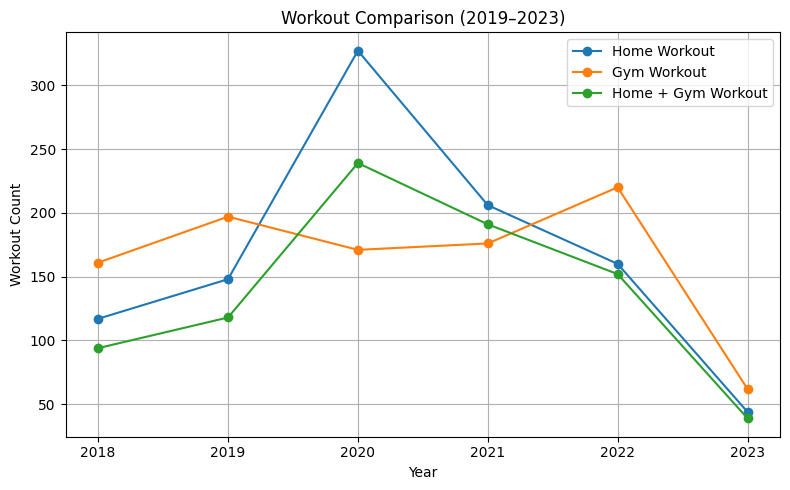

In [15]:
import matplotlib.pyplot as plt

# Example: each Series has years as index
# home_workout_ww, gym_workout_ww, home_gym_ww

plt.figure(figsize=(8, 5))

plt.plot(home_workout_ww.index, home_workout_ww.values, marker='o', label='Home Workout')
plt.plot(gym_workout_ww.index, gym_workout_ww.values, marker='o', label='Gym Workout')
plt.plot(home_gym_ww.index, home_gym_ww.values, marker='o', label='Home + Gym Workout')

plt.title('Workout Comparison (2019–2023)')
plt.xlabel('Year')
plt.ylabel('Workout Count')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [20]:
combined = pd.DataFrame({
    "home_workout": home_workout_ww,
    "gym_workout": gym_workout_ww,
    "home_gym": home_gym_ww
})
combined

,home_workout,gym_workout,home_gym
year,,,
2018,117,161,94
2019,148,197,118
2020,327,171,239
2021,206,176,191
2022,160,220,152
2023,44,62,39


In [23]:
# check if 2020 or 2021 has the highest score and what was the keyword
peak_2020_col = combined.loc['2020'].idxmax()
peak_2020_val = combined.loc['2020'].max()

peak_2021_col = combined.loc['2021'].idxmax()
peak_2021_val = combined.loc['2021'].max()

if peak_2020_val > peak_2021_val:
    peak_covid = peak_2020_col
else:
    peak_covid = peak_2021_col

print(f"peak_covid keyword: {peak_covid}")



peak_covid keyword: home_workout


In [25]:
current = combined.loc['2023'].idxmax()
peak_2023_val = combined.loc['2023'].max()
print(f"current keyword: {current}")

current keyword: gym_workout


## What country has the highest interest for workouts among the following: United States, Australia, or Japan? Save your answer as top_country.

In [26]:
workout_geo_df = pd.read_csv("data/workout_geo.csv")
workout_geo_df.head()

,country,workout_2018_2023
0,Guam,NaN
1,Falkland Islands (Islas Malvinas),NaN
2,Cook Islands,NaN
3,Brunei,NaN
4,Palau,NaN


In [30]:
selected_countries = ["United States", "Australia", "Japan"]

workout_geo_df2 = workout_geo_df[workout_geo_df["country"].isin(selected_countries)]
workout_geo_df2

,country,workout_2018_2023
5,United States,100.0
18,Australia,77.0
216,Japan,1.0


In [34]:
ordered_workout_geo = workout_geo_df2.sort_values(by="workout_2018_2023", ascending=False)
ordered_workout_geo

,country,workout_2018_2023
5,United States,100.0
18,Australia,77.0
216,Japan,1.0


In [43]:
top_country = ordered_workout_geo.iloc[0][ 'country']
print(f"top_country = {top_country}")

top_country = United States


## Question #4: You'd be interested in expanding your virtual home workouts offering to either the Philippines or Malaysia. Which of the two countries has the highest interest in home workouts? Identify the country and save it as home_workout_geo.

In [48]:
three_keywords_geo_df = pd.read_csv("data/three_keywords_geo.csv")
three_keywords_geo_df.head()

,Country,home_workout_2018_2023,gym_workout_2018_2023,home_gym_2018_2023
0,Gibraltar,NaN,NaN,NaN
1,Lesotho,NaN,NaN,NaN
2,Guam,NaN,NaN,NaN
3,Botswana,NaN,NaN,NaN
4,Brunei,NaN,NaN,NaN


In [50]:
interesting_countries = ["Philippines", "Malaysia"]
three_keywords_geo_df2 = three_keywords_geo_df[three_keywords_geo_df["Country"].isin(interesting_countries)]
three_keywords_geo_df2

,Country,home_workout_2018_2023,gym_workout_2018_2023,home_gym_2018_2023
23,Philippines,52.0,38.0,10.0
61,Malaysia,47.0,38.0,15.0


In [53]:
# order the dataframe by "home_gym_2018_2023"
ordered_df = three_keywords_geo_df2.sort_values(by="home_workout_2018_2023", ascending=False)
ordered_df

,Country,home_workout_2018_2023,gym_workout_2018_2023,home_gym_2018_2023
23,Philippines,52.0,38.0,10.0
61,Malaysia,47.0,38.0,15.0


In [55]:
home_workout_geo = ordered_df.iloc[0]["Country"]
print(f"home_workout_geo: {home_workout_geo}")

home_workout_geo: Philippines
